# TP – Prédiction du traitement antidiabétique (`diabetesMed`)

| Objectif métier | Objectif data science |
|---|---|
| Identifier les profils de patients diabétiques qui ne reçoivent pas de traitement médicamenteux, afin d'aider l'hôpital à repérer les cas nécessitant une attention ou une prise en charge adaptée. | Classification binaire : prédire si un patient reçoit un traitement antidiabétique (`diabetesMed` = Yes/No) à partir de ses caractéristiques démographiques et cliniques. |

**Labs** : 1. Préparation des données · 2. Modélisation · 3. Évaluation · 4. Profils des patients sans traitement

## 1. Préparation des données

In [1]:
import pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay

df = pd.read_csv('diabetic_data.csv', na_values='?', low_memory=False)
print(df.shape)
df['diabetesMed'].value_counts(normalize=True)

(101766, 50)


diabetesMed
Yes    0.770031
No     0.229969
Name: proportion, dtype: float64

**Fuite de données** : `diabetesMed = Yes` dès qu'un des 23 médicaments est prescrit, et `change` décrit le changement de ces médicaments. Ces colonnes donnent la réponse : on les supprime.

In [2]:
medicaments = ['metformin','repaglinide','nateglinide','chlorpropamide','glimepiride','acetohexamide','glipizide','glyburide',
 'tolbutamide','pioglitazone','rosiglitazone','acarbose','miglitol','troglitazone','tolazamide','examide','citoglipton',
 'insulin','glyburide-metformin','glipizide-metformin','glimepiride-pioglitazone','metformin-rosiglitazone','metformin-pioglitazone']
print('Vérification de la fuite (1.0 = exacte) :', ((df[medicaments] != 'No').any(axis=1) == (df.diabetesMed == 'Yes')).mean())

df = df.drop_duplicates(subset='patient_nbr')                       # un seul séjour par patient
df = df[~df.discharge_disposition_id.isin([11, 13, 14, 19, 20, 21])] # sans patients décédés / hospice
df = df[df.gender != 'Unknown/Invalid']

# Suppression : fuite, identifiants, colonnes trop vides ou postérieures à la cible, diagnostics et spécialité (simplification)
df = df.drop(columns=medicaments + ['change', 'encounter_id', 'patient_nbr', 'weight', 'payer_code',
                                    'readmitted', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3'])
print(df.shape)

Vérification de la fuite (1.0 = exacte) : 1.0


(69970, 17)


In [3]:
y = (df.diabetesMed == 'Yes').astype(int)          # 1 = traité, 0 = non traité
df = df.drop(columns='diabetesMed')

df['age'] = df.age.str.extract(r'\[(\d+)-').astype(int) + 5   # tranche d'âge -> milieu de la tranche
df['race'] = df.race.fillna('Inconnu')
df['max_glu_serum'] = df.max_glu_serum.fillna('Non mesure')
df['A1Cresult'] = df.A1Cresult.fillna('Non mesure')
for c in ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']:
    df[c] = df[c].astype(str)                       # codes = catégories

X = pd.get_dummies(df, drop_first=True)             # texte -> colonnes 0/1
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X.shape, len(X_train), len(X_test))

(69970, 64) 55976 13994


## 2. Modélisation
`class_weight='balanced'` (ou `scale_pos_weight`) compense le fait que la classe « No » est minoritaire (~23 %).

In [4]:
modeles = {
    'Régression logistique': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced')),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20, class_weight='balanced', random_state=42),
    'XGBoost': XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, eval_metric='logloss', random_state=42,
                             scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum())}
for nom, m in modeles.items():
    m.fit(X_train, y_train)
print('Modèles entraînés')

Modèles entraînés


## 3. Évaluation et comparaison

In [5]:
lignes = []
for nom, m in modeles.items():
    pred = m.predict(X_test)
    lignes.append({'Modèle': nom, 'Accuracy': accuracy_score(y_test, pred),
        'Précision (No)': precision_score(1 - y_test, 1 - pred), 'Rappel (No)': recall_score(1 - y_test, 1 - pred),
        'F1 (No)': f1_score(1 - y_test, 1 - pred), 'AUC': roc_auc_score(y_test, m.predict_proba(X_test)[:, 1])})
resultats = pd.DataFrame(lignes).set_index('Modèle').round(3)
resultats

,Accuracy,Précision (No),Rappel (No),F1 (No),AUC
Modèle,,,,,
Régression logistique,0.612,0.341,0.671,0.452,0.681
Random Forest,0.657,0.364,0.589,0.450,0.687
XGBoost,0.652,0.366,0.629,0.463,0.702


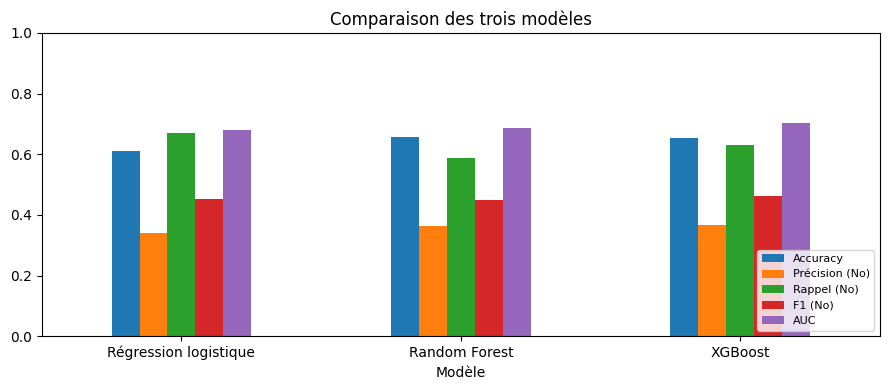

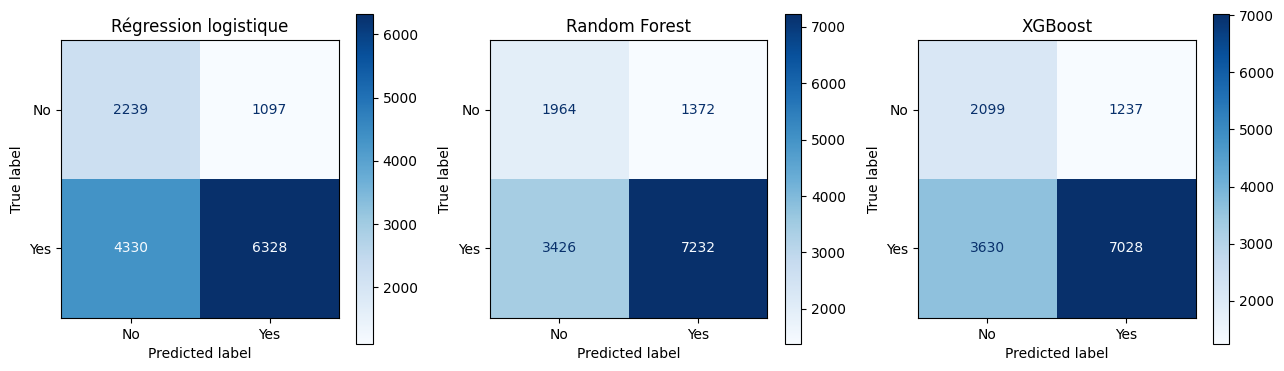

In [6]:
resultats.plot.bar(figsize=(9, 4), rot=0); plt.title('Comparaison des trois modèles'); plt.ylim(0, 1)
plt.legend(loc='lower right', fontsize=8); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, (nom, m) in zip(ax, modeles.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, m.predict(X_test), display_labels=['No', 'Yes'], cmap='Blues', ax=a); a.set_title(nom)
plt.tight_layout(); plt.show()

## 4. Profils des patients sans traitement (objectif métier)

In [7]:
groupe = y.map({0: 'No (sans traitement)', 1: 'Yes (traité)'})
print(df.groupby(groupe)[['age', 'time_in_hospital', 'num_medications', 'number_diagnoses']].mean().T.round(2))
print()
print((pd.crosstab(df['A1Cresult'], groupe, normalize='columns') * 100).round(1))

diabetesMed       No (sans traitement)  Yes (traité)
age                              66.04         65.25
time_in_hospital                  3.91          4.39
num_medications                  12.90         16.53
number_diagnoses                  7.15          7.25

diabetesMed  No (sans traitement)  Yes (traité)
A1Cresult                                      
>7                            3.5           4.3
>8                            3.6          10.6
Non mesure                   86.9          80.0
Norm                          6.0           5.1


### Conclusion
- Les colonnes de médicaments et `change` sont supprimées (fuite de données : elles donnent exactement la cible).
- Trois classifieurs binaires sont comparés sur le même jeu de test : **XGBoost est le meilleur** (AUC 0,70, F1 « No » 0,46), devant Random Forest (0,69) et la régression logistique (0,68). Les écarts sont faibles : la performance est modérée.
- **Profils des patients sans traitement** : ils prennent moins de médicaments pendant l'hospitalisation (≈ 13 contre ≈ 17), ont des séjours un peu plus courts (3,9 contre 4,4 jours), ont plus rarement une HbA1c élevée (> 8 : 3,6 % contre 10,6 %) et celle-ci est moins souvent mesurée (87 % contre 80 %). L'âge est très proche (≈ 66 ans).
- Le modèle sert d'outil de repérage des patients à examiner, à valider avec les cliniciens.